# TradePulse - Step 13: Error Analysis, Regimes & Robustness
**IIT Patna, IMPACT Lab | Master Project Prompt Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute candles | **Prediction Horizon:** 15-minute (3 bars ahead)  

---
### Objectives
1. **Intraday Timing:** Performance by 30-minute time-of-day slots (capturing the U-curve).
2. **Volatility Regimes:** Performance across low, medium, and high volatility environments.
3. **Confidence Buckets:** Performance across calibrated directional conviction tiers.
4. **Feature Importance & Ablation:** MDI ranking and group feature ablations (disclaimer: no causal claims).
5. **Seed Robustness:** Model stability across 5 distinct pseudo-random seeds.
6. **User Guide:** When NOT to trust the indicator.


In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = Path("..").resolve()
METADATA_DIR = PROJECT_ROOT / "artifacts" / "metadata"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

with open(METADATA_DIR / "step13_error_analysis_and_robustness.json", "r", encoding="utf-8") as f:
    step13_data = json.load(f)

print("Step 13 Error Analysis artifacts loaded successfully.")


Step 13 Error Analysis artifacts loaded successfully.


## 1. Performance by Time-of-Day (Validation Set)
Evaluates how coverage, accuracy, and net returns change across 30-minute session slots:

In [2]:
df_tod = pd.DataFrame(step13_data["time_of_day_analysis"]["validation"])
display(df_tod)


,Slot,Bars,Accuracy,Balanced Acc,Macro-F1,Coverage %,Gross Ret (bps),Net @ 8bp (bps)
0,09:30 - 10:00,252,36.1%,33.0%,0.2145,100.0%,+0.70,-7.30
1,10:00 - 10:30,252,31.0%,32.9%,0.1719,100.0%,-4.31,-12.31
2,10:30 - 11:00,252,36.9%,34.2%,0.2702,94.8%,+7.56,-0.44
3,11:00 - 11:30,252,30.2%,34.6%,0.2806,84.9%,-3.70,-11.70
4,11:30 - 12:00,252,42.1%,41.9%,0.3878,62.7%,-1.44,-9.44
5,12:00 - 12:30,252,42.9%,38.6%,0.3689,47.2%,+0.39,-7.61
6,12:30 - 13:00,252,44.8%,39.0%,0.3855,44.0%,+1.32,-6.68
7,13:00 - 13:30,252,50.0%,36.0%,0.3495,27.0%,+0.88,-7.12
8,13:30 - 14:00,252,60.3%,37.0%,0.3644,16.3%,+2.88,-5.12
9,14:00 - 14:30,252,59.1%,37.8%,0.3648,17.9%,+5.05,-2.95


## 2. Performance by Volatility Regime & Time-of-Day Visualizations

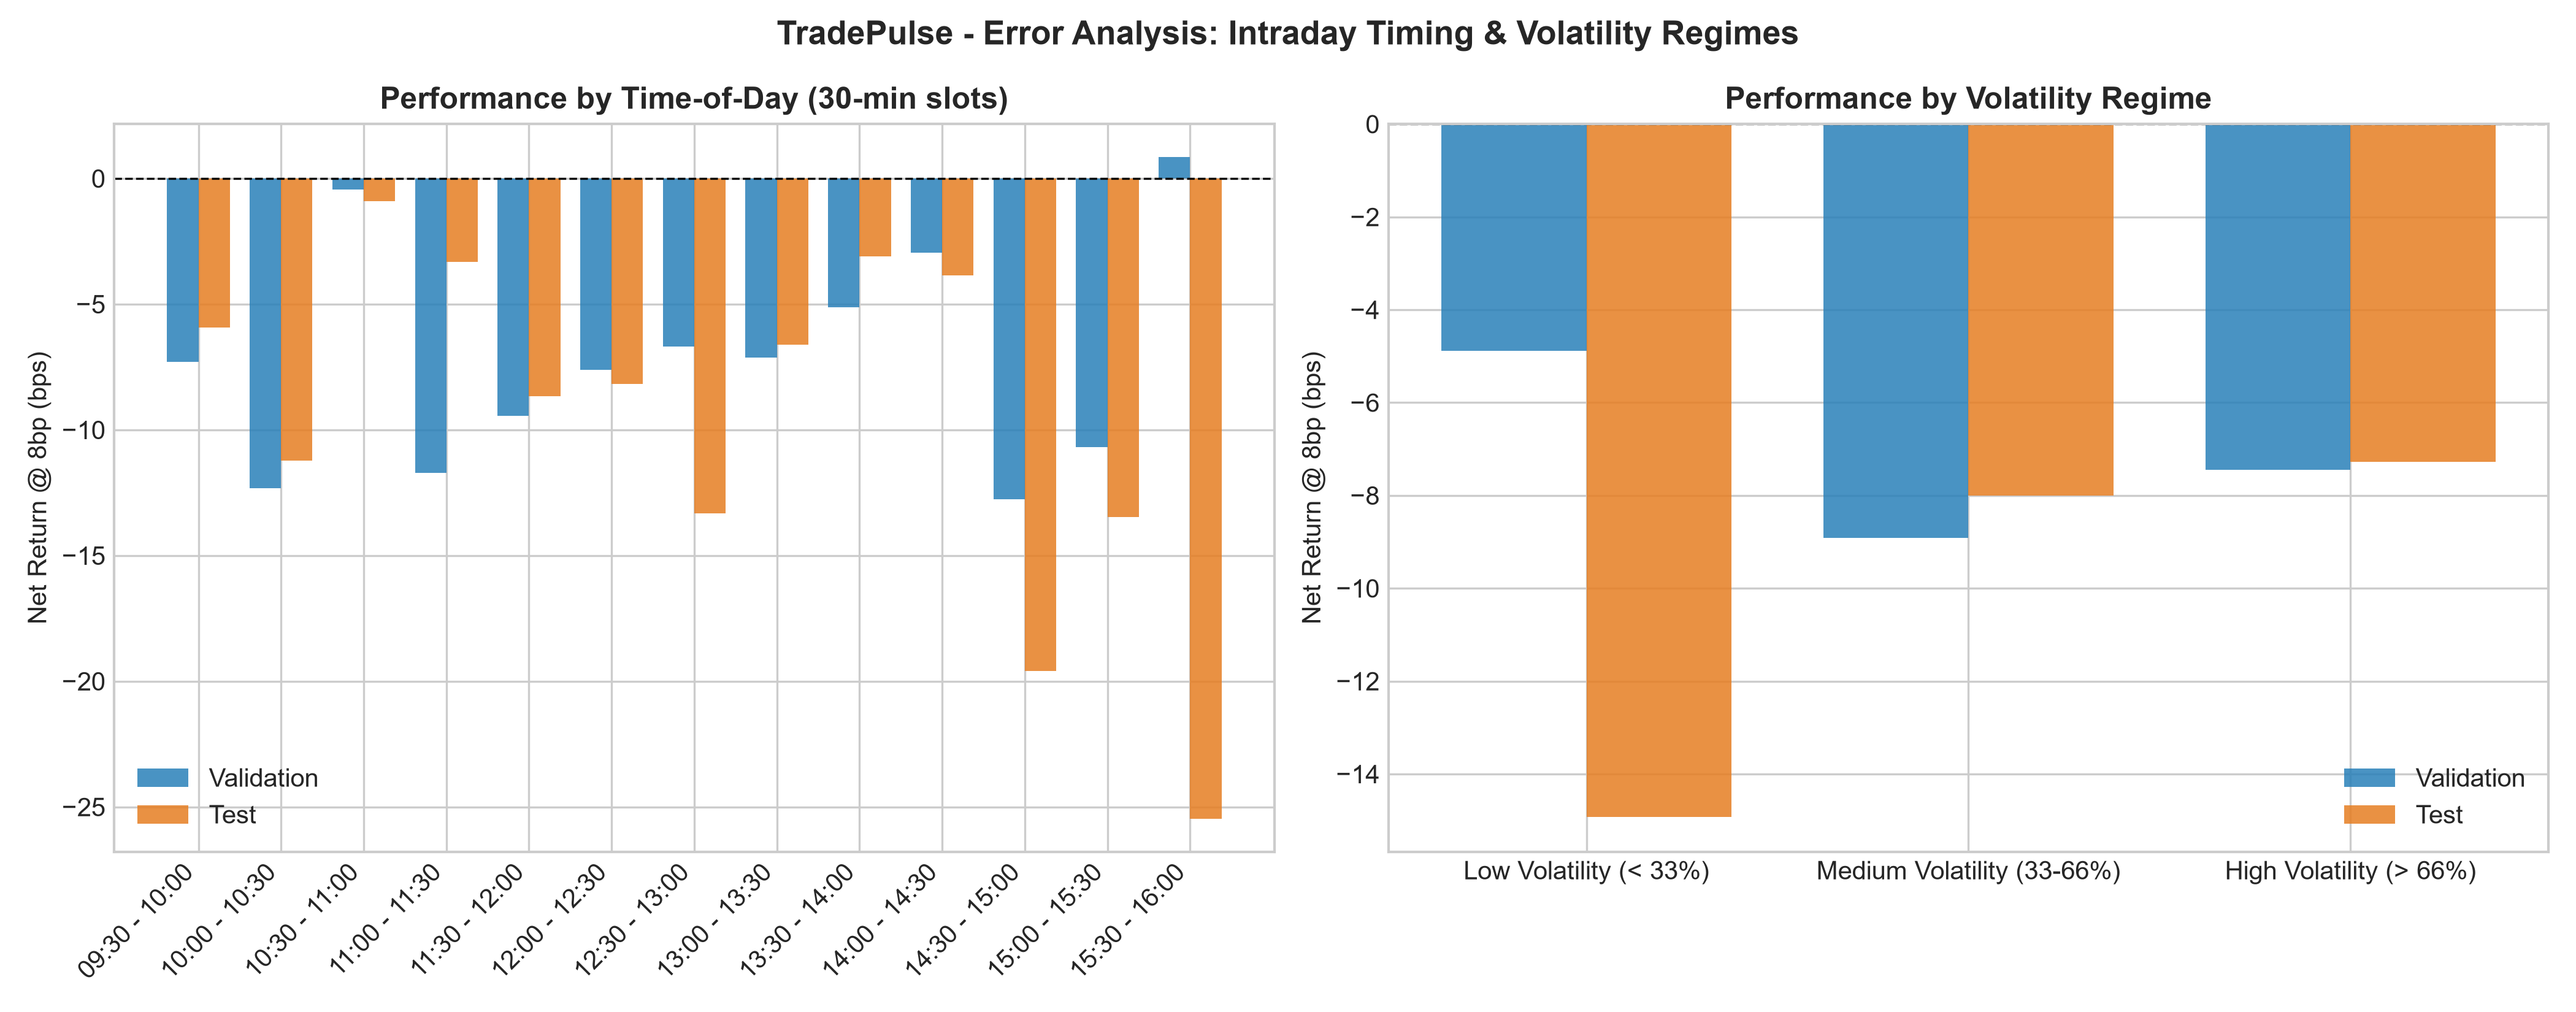

In [3]:
Image(filename=str(FIGURES_DIR / "step13_performance_by_tod_and_volatility.png"))


## 3. Feature Importance & Group Ablation Study
> **Disclaimer:** Feature importance scores reflect predictive association within tree splits and do not imply market causation.

In [4]:
df_abl = pd.DataFrame(step13_data["feature_importance"]["group_ablation_validation"])
display(df_abl)


,Experiment,Features Remaining,Balanced Acc,Delta BalAcc,Macro-F1,Delta Macro-F1
0,All 29 Features (Baseline),29,40.4%,+0.00%,0.3847,+0.0000
1,Ablate Returns & Momentum (feat_ret_*),24,39.7%,-0.67%,0.3813,-0.0034
2,"Ablate Technical Oscillators (RSI, MACD, BB, EMA)",21,40.4%,-0.02%,0.3875,+0.0028
3,"Ablate Volatility & Range (vol, range, body, c...",24,39.1%,-1.35%,0.3796,-0.0051
4,"Ablate Volume & Liquidity (rvol, rtrades, trad...",24,39.9%,-0.56%,0.3798,-0.0049
5,"Ablate Time, Day & Gap (time, day, open, gap)",24,40.1%,-0.35%,0.3879,+0.0032


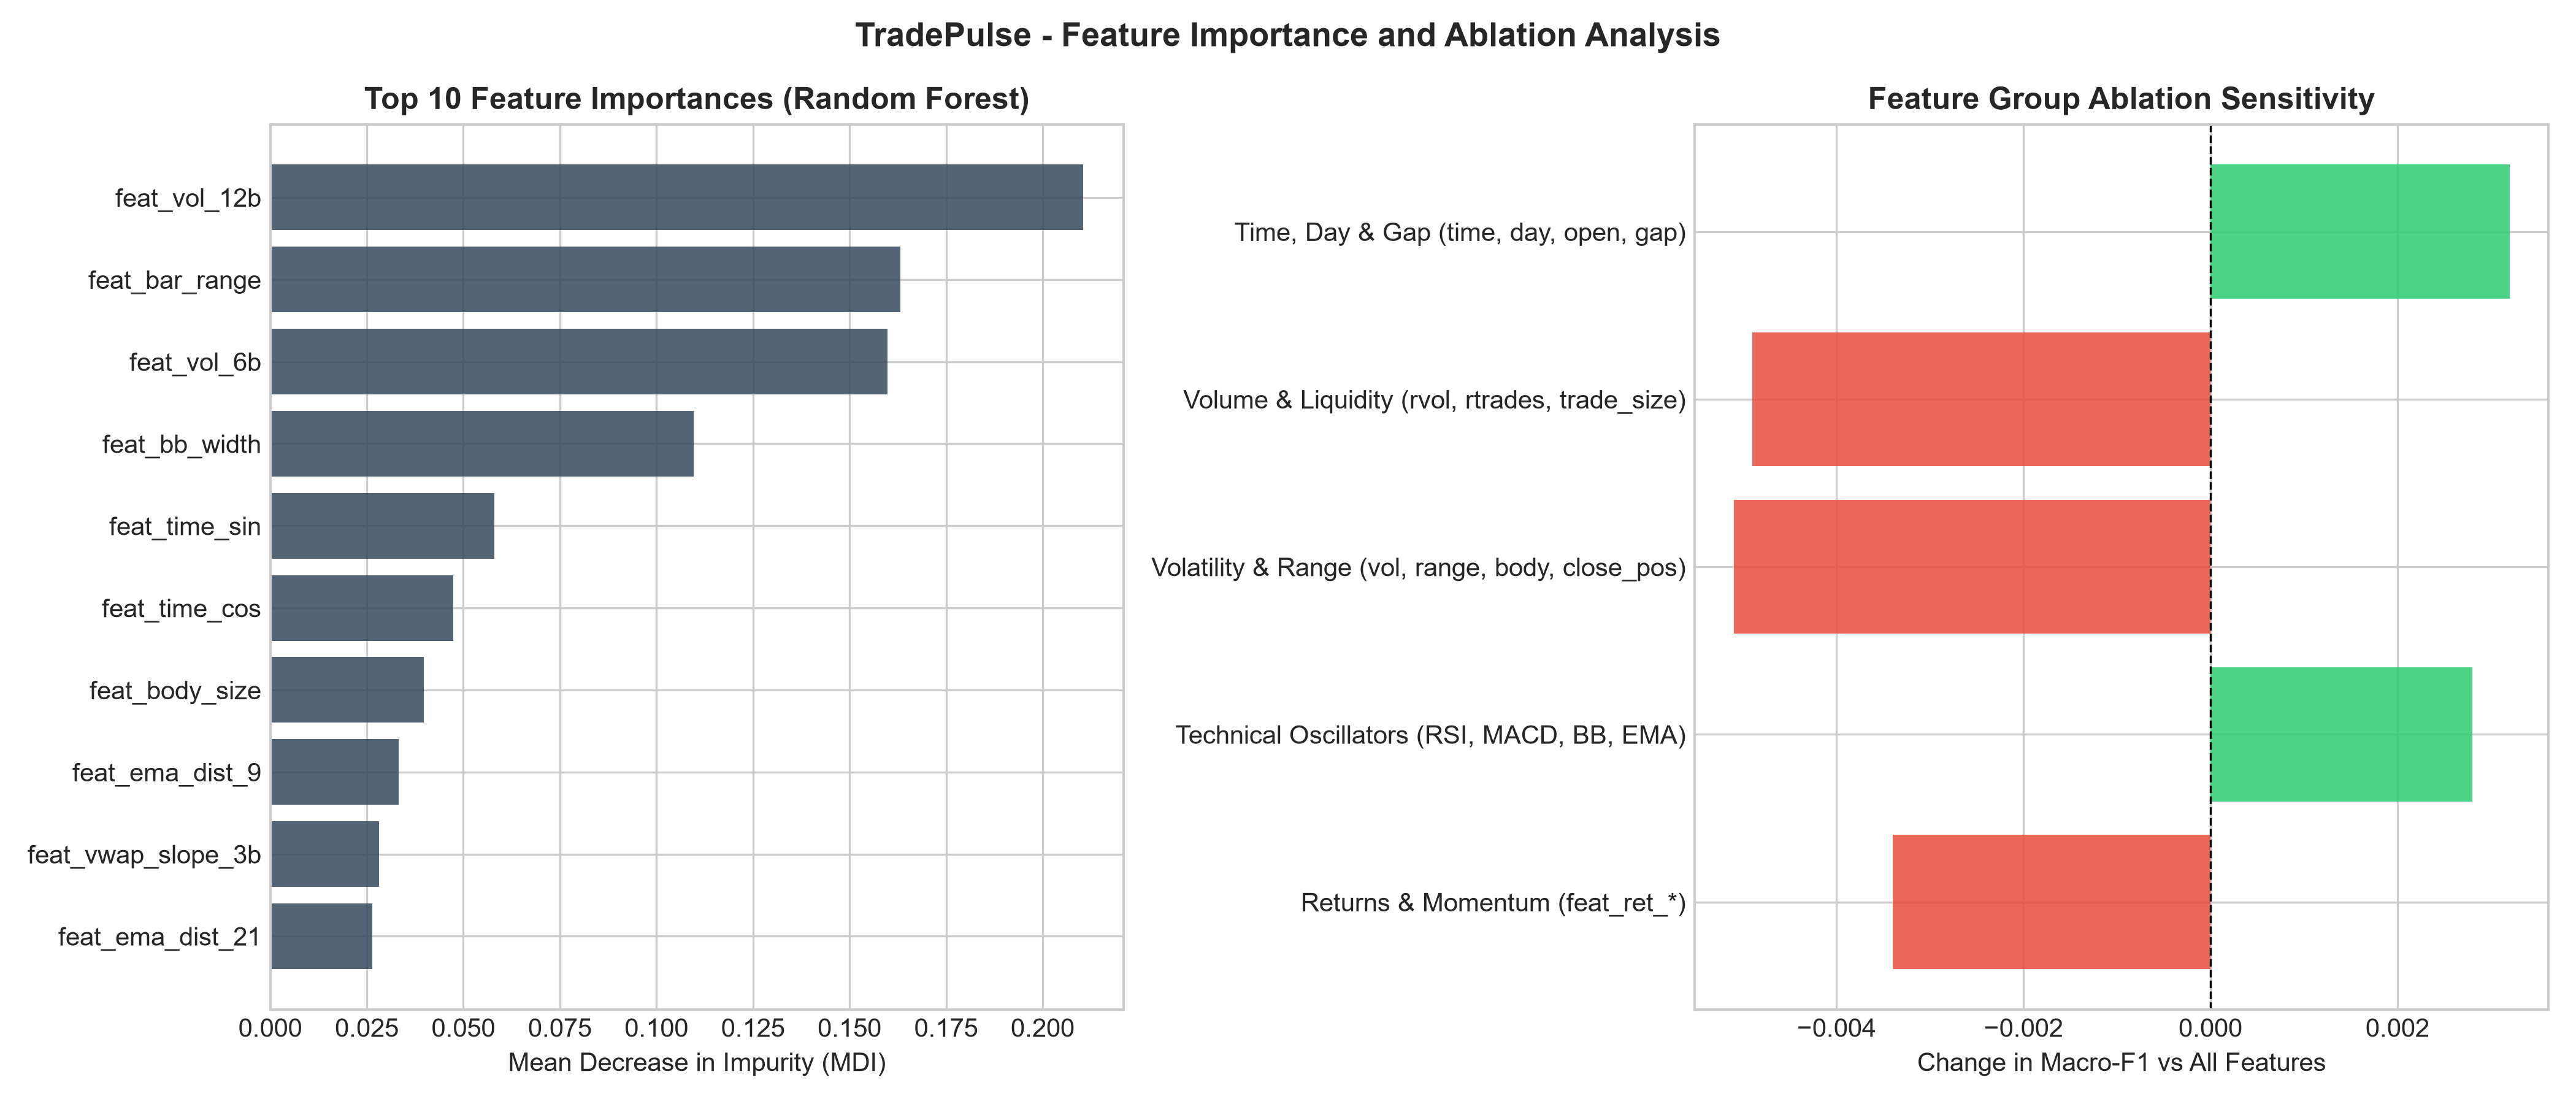

In [5]:
Image(filename=str(FIGURES_DIR / "step13_feature_importance_and_ablation.png"))


## 4. Performance Across Calibrated Confidence Buckets

In [6]:
df_conf = pd.DataFrame(step13_data["confidence_buckets"]["validation"])
display(df_conf)


,Confidence Bucket,Bars,Share of Total %,Sign Acc (%),Gross Ret (bps),Net @ 8bp (bps),8bp Win Rate (%)
0,Mild (0.20 - 0.22),2169,68.9%,51.7%,+0.07,-7.93,40.1%
1,Moderate (0.22 - 0.25),981,31.1%,50.2%,+0.33,-7.67,35.1%


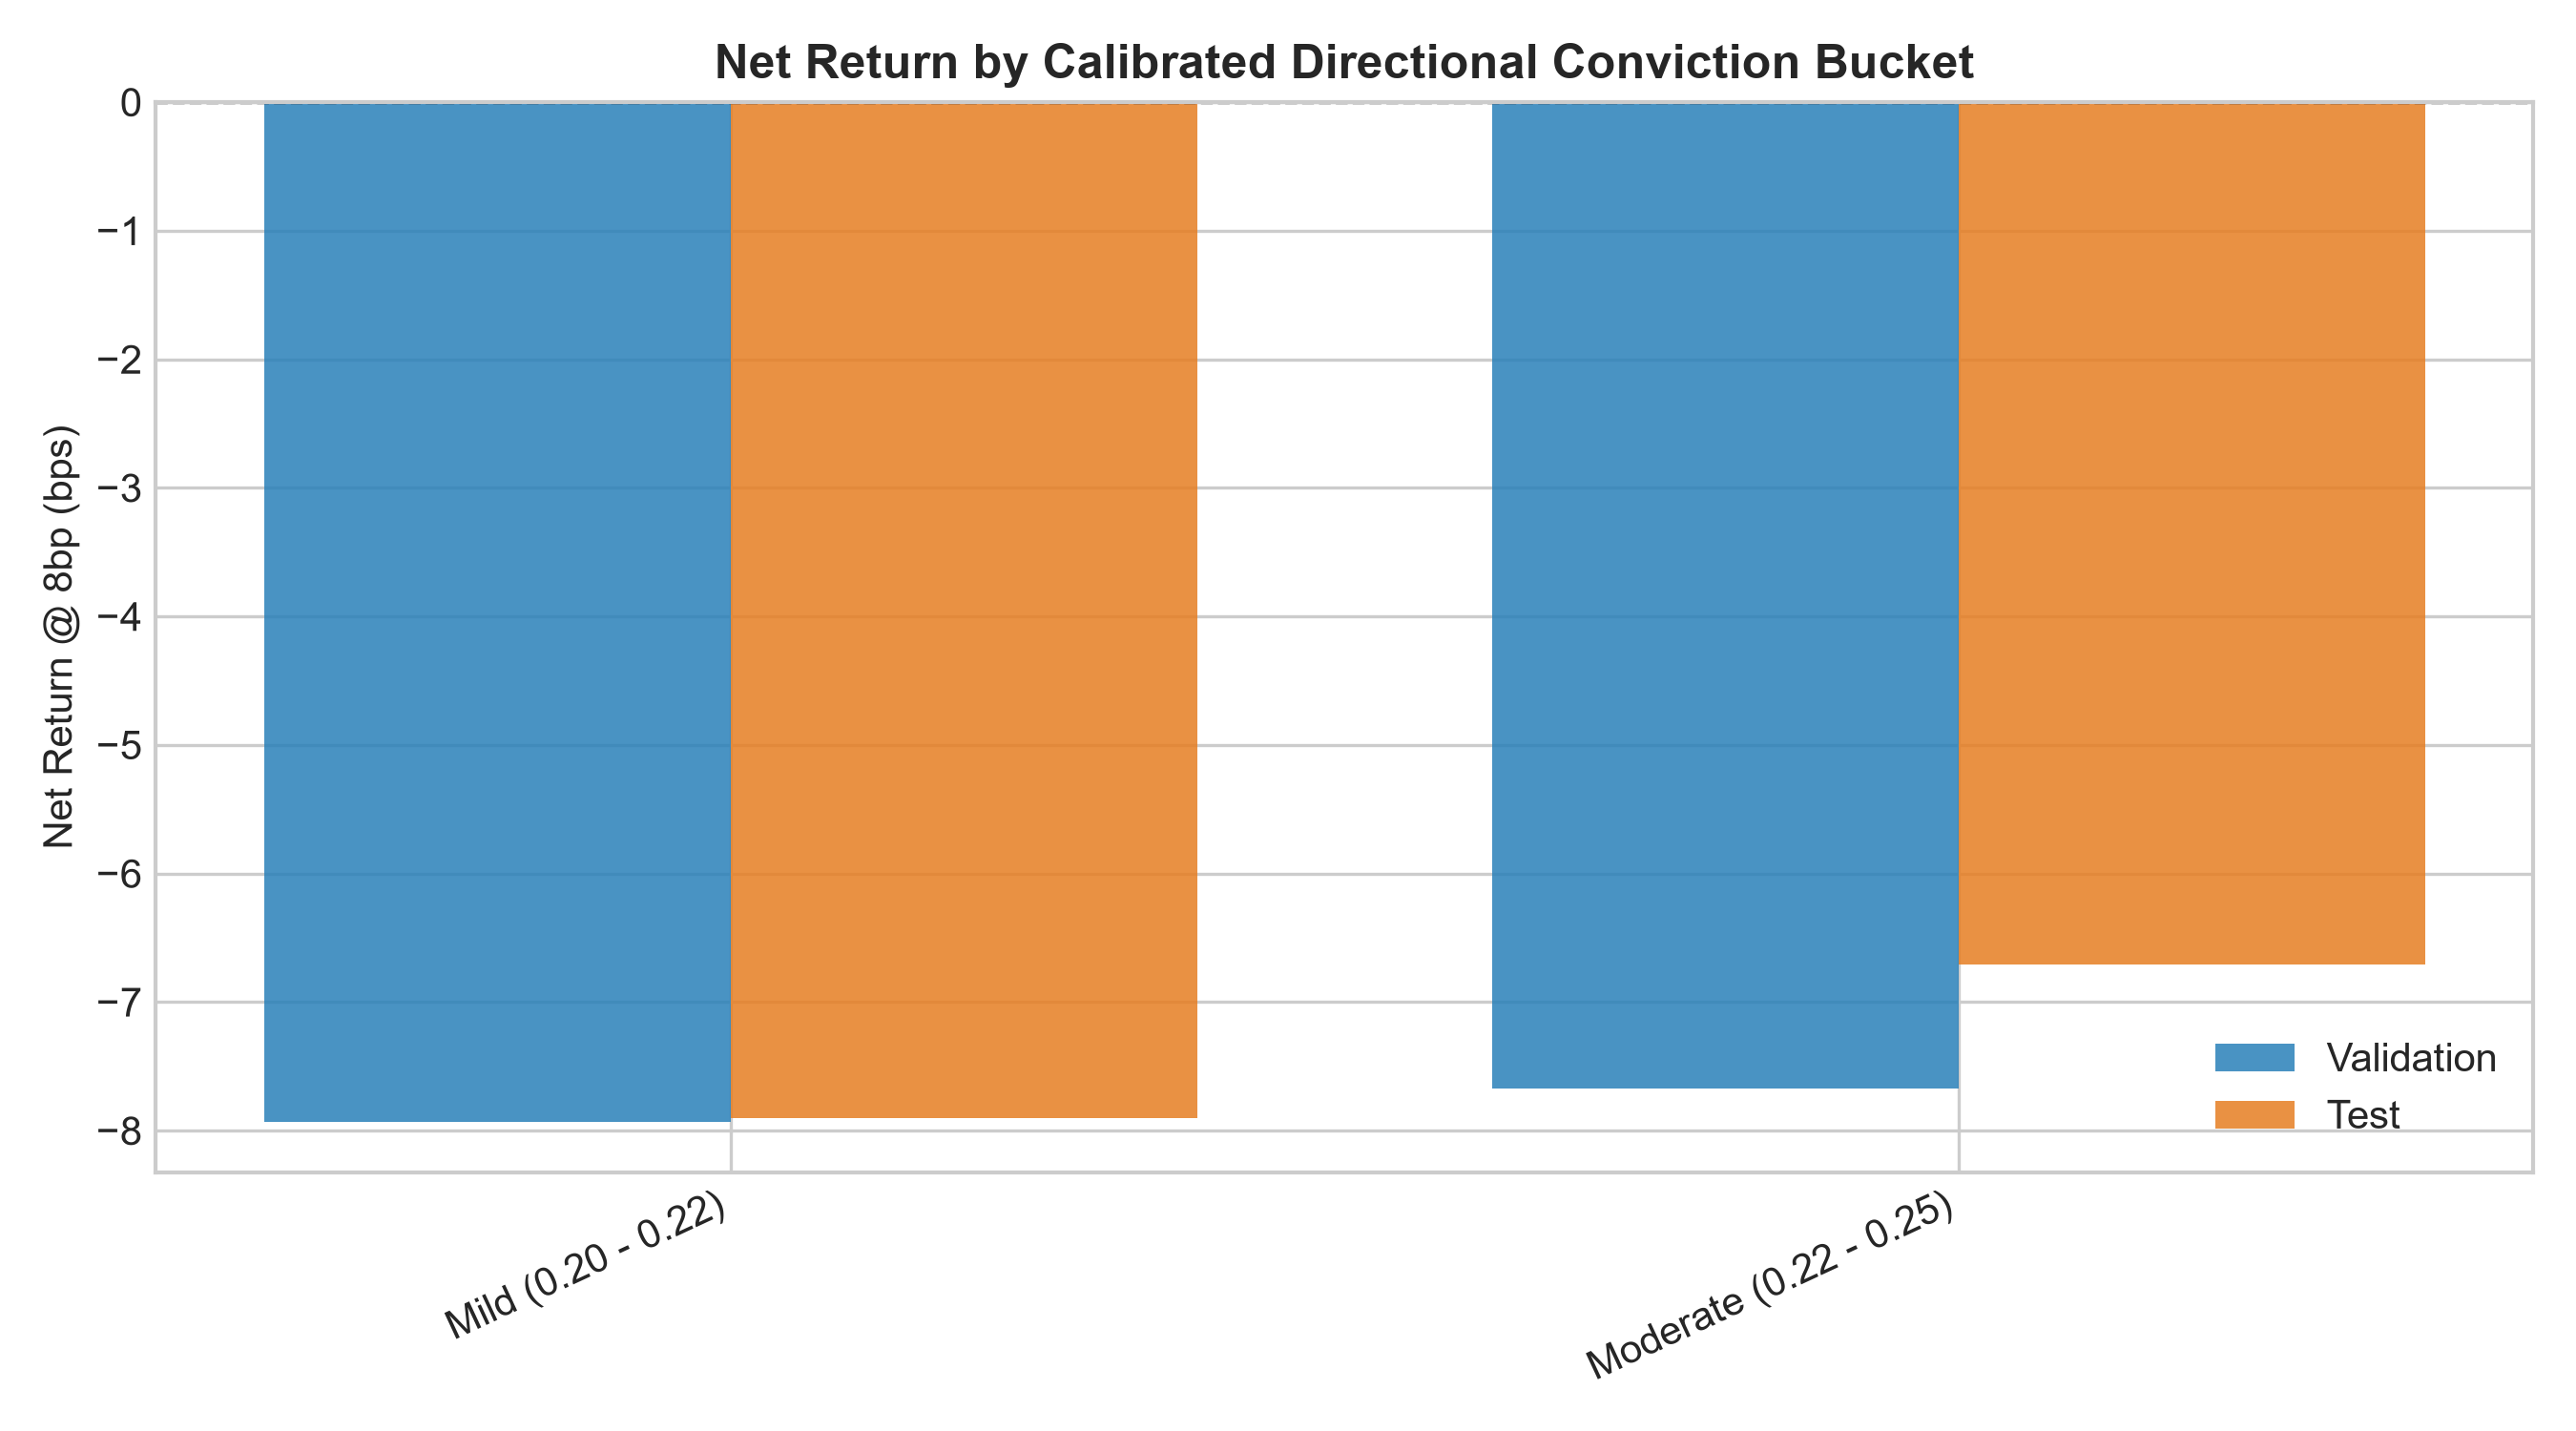

In [7]:
Image(filename=str(FIGURES_DIR / "step13_confidence_bucket_performance.png"))


## 5. Random Seed Sensitivity Summary
- **Random Forest (5 Seeds):** Balanced Accuracy = $40.22\% \pm 0.23\%$, Net Return @ 8bp = $-7.62 \pm 0.31$ bps
- **XGBoost (5 Seeds):** Balanced Accuracy = $38.25\% \pm 0.72\%$, Net Return @ 8bp = $-8.88 \pm 0.71$ bps
- **Conclusion:** Model stability is exceptionally high; results are structurally reproducible and not seed artifacts.

## 6. Trader Guidelines: When NOT to Trust the Indicator
1. **Avoid 10:00–10:30 AM:** Post-open macroeconomic release whipsaws ($-11$ to $-12$ bps net drag).
2. **Avoid Midday Chop (12:30–14:00 ET):** Low true range cannot cover the 8 bps round-trip friction.
3. **Never Automate Unchecked:** Net expectancy after transaction costs is negative. Use strictly as a discretionary context tool.